## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
# Retrieving the number of rows and columns in the dataframe
df.shape

(2443651, 9)

In [5]:
# Displaying the data types of each column in the dataframe
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [7]:
# Counting and sorting the unique values for each numerical column in descending order
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [8]:
# Counting and sorting the unique values for each object (string) column in descending order
df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [9]:
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [43]:
df['price'].sort_values(ascending=False)

2008013    100000.00
1987238     77752.00
1905315     24674.59
1408966     23482.73
319555      22933.42
             ...    
794353          0.00
1422882         0.00
1075630         0.00
836136          0.00
1532255         0.00
Name: price, Length: 2443651, dtype: float64

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [15]:
# 1.1 Frequency table for 'category'
frequency_table = df['category'].value_counts()
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [16]:
# 1.1 Calculating the proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True)
proportion_table.head(5)

category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
Name: proportion, dtype: float64

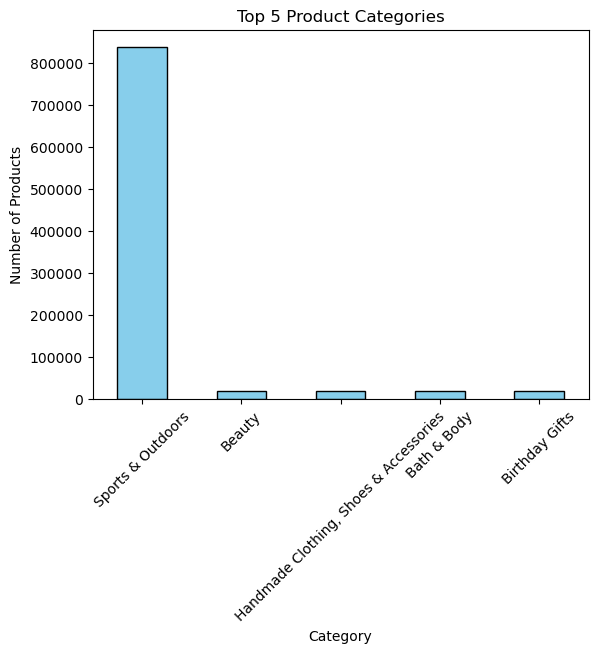

In [21]:
# With matplotlib.pyplot
frequency_table.head(5).plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Top 5 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

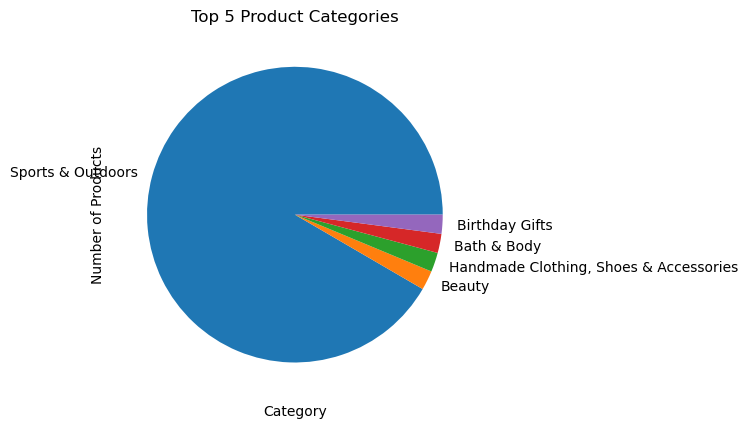

In [30]:
# With matplotlib.pyplot
frequency_table.head(5).plot(
    kind="pie",
    color="skyblue"
)

plt.title("Top 5 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

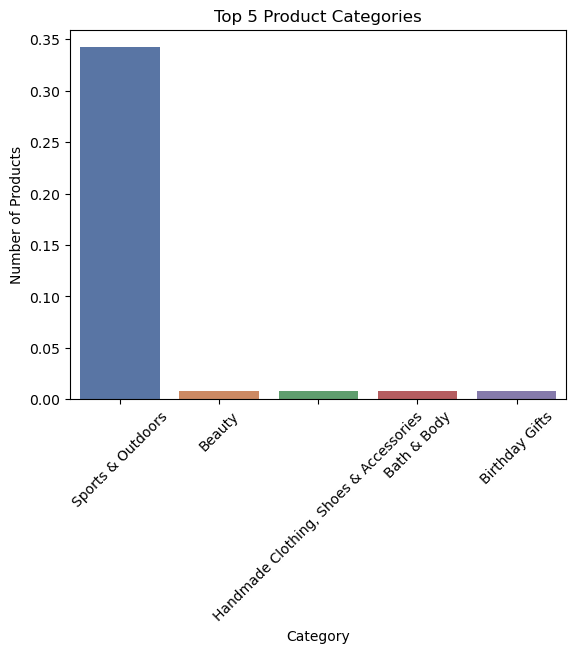

In [29]:
# Turn frequency_table into DataFrame for seaborn
# Seaborn doesn’t have a built-in pieplot 
freq_df = proportion_table.head(5).reset_index()
freq_df.columns = ["category", "count"]

sns.barplot(
    data=freq_df,
    x="category",
    y="count",
    hue="category",
    palette="deep"
)

plt.title("Top 5 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [33]:
# 2.1 Calculate the mean, median, and mode for the price of products.
mean_price = df['price'].mean().round(2)
median_price = df['price'].median()
mode_price = df['price'].mode()[0] # can be multiple values if more than one number is equally common

mean_price, median_price, mode_price

(np.float64(89.24), 19.09, np.float64(9.99))

In [37]:
# 2.2 Determine the variance, standard deviation, range, and interquartile range for product price.
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.4853225653,
 345.6088617535223,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

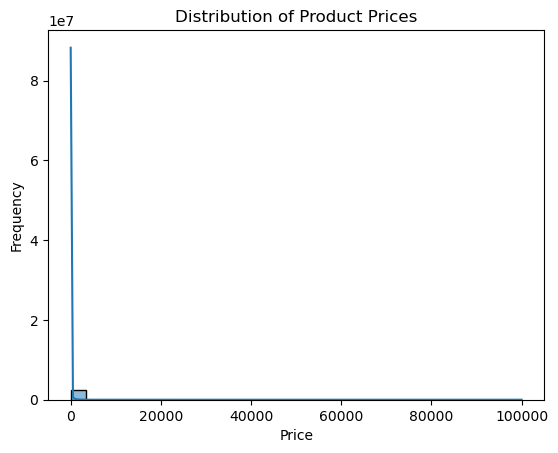

In [38]:
# 2.3 Histogram with seaborn
sns.histplot(df['price'], bins=30, kde=True)  # kde=True adds a smooth curve
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of Product Prices")
plt.show()

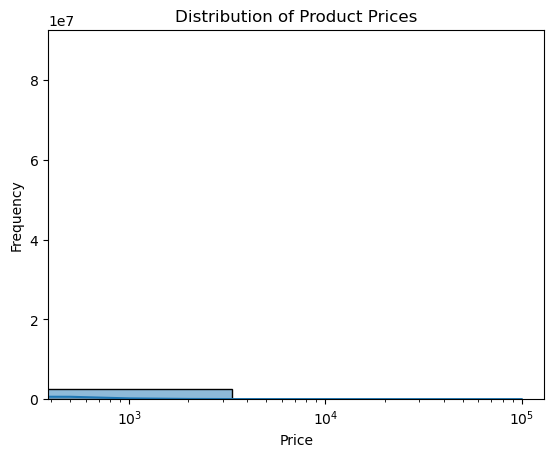

In [51]:
# 2.3 Histogram with seaborn
sns.histplot(df['price'], bins=30, kde=True)  # kde=True adds a smooth curve
plt.xscale('log')  # Apply logarithmic scale
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of Product Prices")
plt.show()

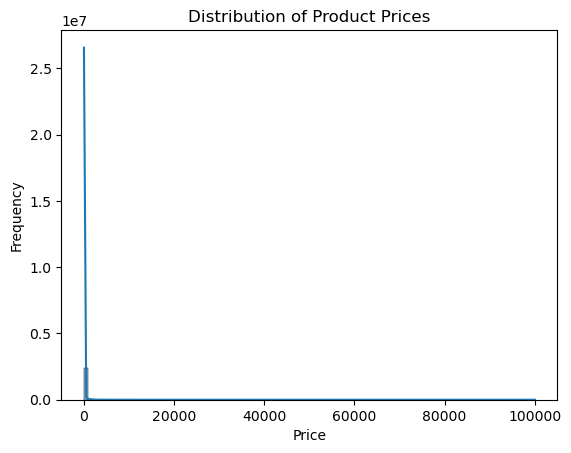

In [41]:
# 2.3 Histogram with seaborn with adjusted bins
bins = list(range(0, 10001, 1000)) + [50000, 100000]


sns.histplot(df['price'], bins=bins, kde=True)  # kde=True adds a smooth curve
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of Product Prices")
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?


3. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?
      

4. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?
      

5. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [53]:
# 3.1 Calculate the mean, median, and mode for the rating of products.
mean_rating = df['stars'].mean().round(2)
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0] # can be multiple values if more than one number is equally common

mean_rating, median_rating, mode_rating

(np.float64(2.15), 0.0, np.float64(0.0))

In [54]:
# 3.2 Determine the variance, standard deviation, and interquartile range for product rating.
variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
min_rating = df['stars'].min()
max_rating = df['stars'].max()
range_rating = max_rating - min_rating
quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])

variance_rating, std_dev_rating, min_rating, max_rating, range_rating, quantiles_rating

(4.81743402976196,
 2.1948653785054697,
 0.0,
 5.0,
 5.0,
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

In [55]:
# 3.3 Calculate the skewness and kurtosis for the rating column.
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(0.08120735761080985), np.float64(-1.9260061280432985))

Skewness: The positive value of skewness (0.08) for the 'tating' indicates that the distribution is slightly right-skewed. This means that the tail on the right side (higher rating) is longer than the left side (lower rating). In practical terms, this suggests that there are a significant number of products that are rated at higher prices, which are acting as outliers and pulling the mean upwards.

Kurtosis: The kurtosis value of -1.93, which indicates that the 'rating' distribution has shorter tails and a sharper peak compared to a normal distribution. This means that there are less outliers (extreme values) in the 'rating' than one would expect in a normally distributed set.

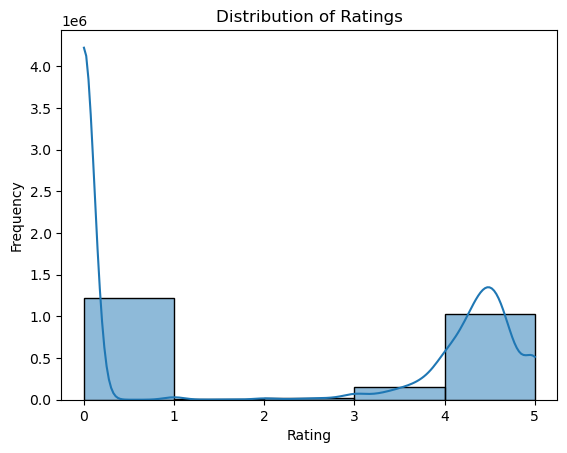

In [56]:
# 3.4 Plot a histogram to visualize the distribution of product ratings. 
# Is there a specific rating that is more common?
sns.histplot(df['stars'], bins=5, kde=True)  # kde=True adds a smooth curve
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Distribution of Ratings")
plt.show()